# 09 – Đánh giá chuyên sâu, chi phí kinh doanh, XAI, đạo đức AI (P5 + P1.4)

⚠️ **Chạy lại toàn bộ notebook này sau khi gán xong tập vàng.** Khi chưa đủ 50 câu nhãn tay, notebook TẠM dùng nhãn sao của kho vàng. Lúc đó:
- mọi con số chỉ để thử code;
- riêng phân tích chi phí "lọc theo sao" sẽ **đúng tuyệt đối một cách giả tạo**, vì nhãn chính là sao.

Nội dung:
1. Chỉ số đầy đủ: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, khoảng tin cậy bootstrap.
2. Ma trận nhầm lẫn và **chi phí kinh doanh** → ROI (đưa lên P1.4).
3. Human-in-the-loop: chuyển câu không chắc chắn cho người.
4. Fairness: theo ngành hàng, theo văn bản không dấu.
5. XAI: giá trị SHAP của mô hình tuyến tính (toàn cục và từng câu).
6. Xuất câu sai để phân tích lỗi.

In [1]:
import sys, os, joblib
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize
from src.data import load_sets, load_gold, LABELS

FIG, REP, MOD = "../figures", "../report", "../models"
rng = np.random.default_rng(42)
gold, GOLD_TEMP = load_gold()
TAG = "TẠM – nhãn sao" if GOLD_TEMP else "nhãn tay"
print(f"Tập vàng ({TAG}): {len(gold)} câu", gold.label.value_counts().to_dict())
A_test = load_sets()["A_test"]
Xg, Xt = gold[["text_prep", "text_raw"]], A_test[["text_prep", "text_raw"]]

Tập vàng (TẠM – nhãn sao): 746 câu {'pos': 536, 'neg': 160, 'neu': 50}


## 1. Nạp mô hình và tính xác suất

- LinearSVC không có xác suất. Dùng `decision_function` làm điểm số để tính AUC; AUC chỉ cần thứ tự điểm, không cần xác suất.
- PhoBERT: đọc kết quả từ Colab (`report/phobert/`) nếu đã có.

In [2]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    return np.exp(z) / np.exp(z).sum(1, keepdims=True)

models = {"BoW+NB (baseline)": "bow_nb_AB", "TF-IDF+LR": "tfidf_lr_AB",
          "TF-IDF+LinearSVC": "tfidf_svc_AB", "TF-IDF+đặc trưng+LR": "tfidf_feat_lr_AB"}
scores, scores_test, fitted = {}, {}, {}
for name, fn in models.items():
    m = joblib.load(f"{MOD}/{fn}.joblib")
    fitted[name] = m
    f = m.predict_proba if hasattr(m, "predict_proba") else (lambda X, m=m: softmax(m.decision_function(X)))
    scores[name], scores_test[name] = f(Xg), f(Xt)

PB = "../report/phobert"
if os.path.exists(f"{PB}/phobert_gold_pool_proba.csv"):
    pb = pd.read_csv(f"{PB}/phobert_gold_pool_proba.csv").set_index("id")
    scores["PhoBERT"] = pb.loc[gold.id, ["p_neg", "p_neu", "p_pos"]].values
    scores_test["PhoBERT"] = pd.read_csv(f"{PB}/phobert_visd_test_proba.csv")[["p_neg", "p_neu", "p_pos"]].values
    print("Đã nạp PhoBERT")
else:
    print("Chưa có kết quả PhoBERT (chạy notebook 08 trên Colab).")

Chưa có kết quả PhoBERT (chạy notebook 08 trên Colab).


## 2. Bảng chỉ số chính

**Metric chính: F1-macro**, vì lớp lệch (neu hiếm), và **Recall lớp neg**, vì với chủ shop bỏ sót một lời chê tốn kém hơn đọc nhầm một lời khen. Accuracy chỉ để tham khảo.

In [3]:
Y = label_binarize(gold.label, classes=LABELS)
rows = []
for name, P in scores.items():
    pred = np.array(LABELS)[P.argmax(1)]
    rows.append({"Mô hình": name,
                 "Accuracy": accuracy_score(gold.label, pred),
                 "Precision (macro)": precision_score(gold.label, pred, average="macro", zero_division=0),
                 "Recall (macro)": recall_score(gold.label, pred, average="macro"),
                 "F1-macro": f1_score(gold.label, pred, average="macro"),
                 "Recall neg": recall_score(gold.label, pred, labels=["neg"], average="macro"),
                 "ROC-AUC (OvR)": roc_auc_score(Y, P, average="macro"),
                 "PR-AUC (macro)": average_precision_score(Y, P, average="macro"),
                 "F1 ViSD test": f1_score(A_test.label, np.array(LABELS)[scores_test[name].argmax(1)], average="macro")})
main = pd.DataFrame(rows).set_index("Mô hình").round(3)
main.to_csv(f"{REP}/main_results.csv", encoding="utf-8-sig")
BEST = main["F1-macro"].idxmax()
# LinearSVC không có xác suất thật (softmax của decision_function không hiệu chỉnh), nên các phân tích
# cần ngưỡng xác suất (chi phí, Human-in-the-loop, câu sai) dùng mô hình xác suất tốt nhất.
BEST_P = main.drop(index="TF-IDF+LinearSVC")["F1-macro"].idxmax()
print("Mô hình xác suất tốt nhất (dùng cho chi phí, HITL):", BEST_P)
print("Mô hình tốt nhất theo F1-macro trên tập vàng:", BEST)
main

Mô hình xác suất tốt nhất (dùng cho chi phí, HITL): TF-IDF+LR
Mô hình tốt nhất theo F1-macro trên tập vàng: TF-IDF+LinearSVC


,Accuracy,Precision (macro),Recall (macro),F1-macro,Recall neg,ROC-AUC (OvR),PR-AUC (macro),F1 ViSD test
Mô hình,,,,,,,,
BoW+NB (baseline),0.861,0.543,0.585,0.563,0.794,0.814,0.615,0.595
TF-IDF+LR,0.843,0.609,0.615,0.612,0.750,0.904,0.650,0.713
TF-IDF+LinearSVC,0.855,0.619,0.617,0.617,0.762,0.911,0.658,0.708
TF-IDF+đặc trưng+LR,0.839,0.598,0.597,0.597,0.731,0.902,0.649,0.707


In [4]:
print(f"Báo cáo từng lớp – {BEST} ({TAG})")
print(classification_report(gold.label, np.array(LABELS)[scores[BEST].argmax(1)], digits=3))

Báo cáo từng lớp – TF-IDF+LinearSVC (TẠM – nhãn sao)
              precision    recall  f1-score   support

         neg      0.739     0.762     0.751       160
         neu      0.179     0.140     0.157        50
         pos      0.939     0.950     0.944       536

    accuracy                          0.855       746
   macro avg      0.619     0.617     0.617       746
weighted avg      0.845     0.855     0.850       746



### Khoảng tin cậy bootstrap 95%

Tập vàng nhỏ nên F1 dao động. Lấy mẫu lại có hoàn lại 1.000 lần. Hai mô hình có khoảng tin cậy chồng nhau nhiều thì **chưa đủ bằng chứng** để nói mô hình nào tốt hơn.

In [5]:
def boot_f1(y, pred, n=1000):
    y, pred = np.asarray(y), np.asarray(pred)
    idx = rng.integers(0, len(y), (n, len(y)))
    return np.array([f1_score(y[i], pred[i], average="macro") for i in idx])

ci, boots = [], {}
for name, P in scores.items():
    b = boot_f1(gold.label, np.array(LABELS)[P.argmax(1)])
    boots[name] = b
    ci.append({"Mô hình": name, "F1-macro": main.loc[name, "F1-macro"],
               "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5)})
ci = pd.DataFrame(ci).set_index("Mô hình").round(3)
ci.to_csv(f"{REP}/bootstrap_ci.csv", encoding="utf-8-sig")
ci

,F1-macro,CI 2.5%,CI 97.5%
Mô hình,,,
BoW+NB (baseline),0.563,0.542,0.584
TF-IDF+LR,0.612,0.568,0.655
TF-IDF+LinearSVC,0.617,0.576,0.662
TF-IDF+đặc trưng+LR,0.597,0.557,0.636


In [6]:
# Bootstrap ghép cặp: mô hình tốt nhất hơn baseline bao nhiêu, có chắc không?
y = gold.label.values
pb_, pbase = np.array(LABELS)[scores[BEST].argmax(1)], np.array(LABELS)[scores["BoW+NB (baseline)"].argmax(1)]
idx = rng.integers(0, len(y), (1000, len(y)))
diff = np.array([f1_score(y[i], pb_[i], average="macro") - f1_score(y[i], pbase[i], average="macro") for i in idx])
print(f"{BEST} − baseline: {diff.mean():+.3f}, CI95 [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}],"
      f" P(chênh > 0) = {(diff > 0).mean():.2f}")

TF-IDF+LinearSVC − baseline: +0.054, CI95 [+0.015, +0.095], P(chênh > 0) = 1.00


### Đường Precision–Recall và ma trận nhầm lẫn

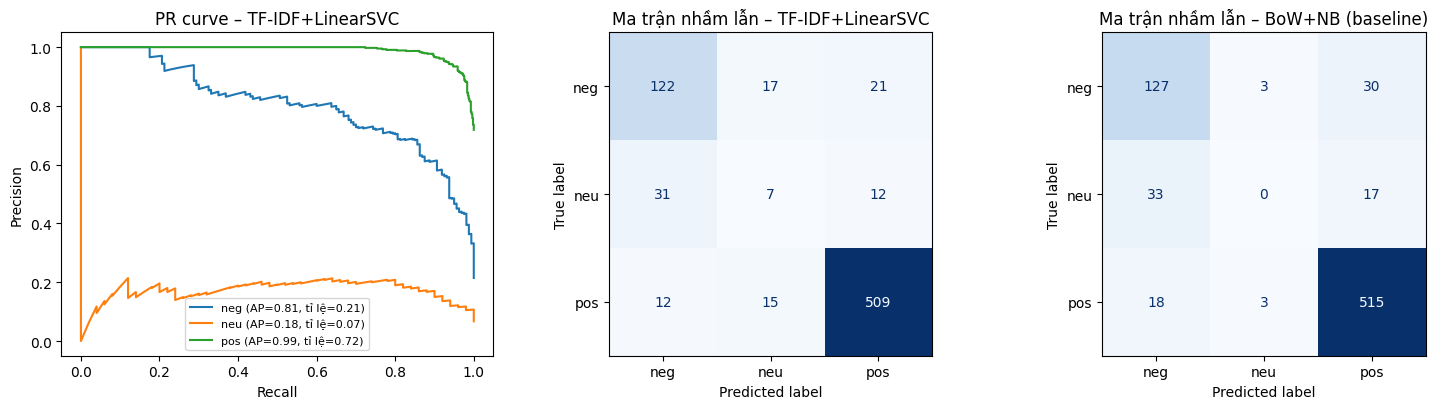

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
P = scores[BEST]
for k, lab in enumerate(LABELS):
    pr, rc, _ = precision_recall_curve(Y[:, k], P[:, k])
    ax[0].plot(rc, pr, label=f"{lab} (AP={average_precision_score(Y[:, k], P[:, k]):.2f}, tỉ lệ={Y[:, k].mean():.2f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title=f"PR curve – {BEST}"); ax[0].legend(fontsize=8)
for a, name in zip(ax[1:], [BEST, "BoW+NB (baseline)"]):
    ConfusionMatrixDisplay.from_predictions(gold.label, np.array(LABELS)[scores[name].argmax(1)], labels=LABELS,
                                            ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Ma trận nhầm lẫn – {name}")
plt.tight_layout(); plt.savefig(f"{FIG}/eval_pr_cm.png", bbox_inches="tight"); plt.show()

**Đọc PR curve:** đường nằm ngang ở mức "tỉ lệ" là mô hình đoán bừa. PR-AUC của lớp neu thường thấp nhất vì lớp này hiếm và khó định nghĩa.

## 3. Chi phí kinh doanh của ma trận nhầm lẫn và ROI

**Bài toán của chủ shop:** mỗi tháng có N review. Review **tiêu cực** cần được đọc và phản hồi (xin lỗi, đổi trả, voucher) để giữ khách.

| Chiến lược | Đọc những review nào |
|---|---|
| (a) Đọc tay toàn bộ | tất cả |
| (b) **Lọc theo sao** (cách làm phổ biến hiện nay) | review 1–2 sao |
| (c) Mô hình | review mô hình dự đoán neg |

- **Sai loại 1 (FP)**: đọc một review không tiêu cực, tốn `C_READ`.
- **Sai loại 2 (FN)**: bỏ sót một review tiêu cực, tốn `C_MISS` (khách không được xử lý, có thể bỏ shop, đánh giá xấu lan truyền).

⚠️ **Mọi con số dưới đây là GIẢ ĐỊNH.** Sửa cho phù hợp và ghi rõ trong báo cáo.

In [8]:
ASSUME = {
    "N_review_thang": 3000,        # review mỗi tháng (shop vừa, nhiều sản phẩm)
    "C_READ": 1_000,               # đọc + phân loại 1 review ≈ 30 giây × lương CSKH 120.000đ/giờ
    "C_MISS": 50_000,              # kỳ vọng thiệt hại khi bỏ sót 1 review chê ≈ 20% khả năng mất khách × 250.000đ lợi nhuận/khách
    "CHI_PHI_TRIEN_KHAI": 15_000_000,   # một lần: tích hợp, kiểm thử
    "CHI_PHI_VAN_HANH_THANG": 500_000,  # máy chủ nhỏ + bảo trì
}
pd.Series(ASSUME, name="Giả định")

N_review_thang                3000
C_READ                        1000
C_MISS                       50000
CHI_PHI_TRIEN_KHAI        15000000
CHI_PHI_VAN_HANH_THANG      500000
Name: Giả định, dtype: int64

In [9]:
is_neg = (gold.label == "neg").values
def strategy_cost(flag, a=ASSUME):
    """flag: mảng bool, review nào được đọc. Trả về chi phí/tháng phóng theo N."""
    scale = a["N_review_thang"] / len(flag)
    fn = (is_neg & ~flag).sum()
    return {"Số review phải đọc/tháng": flag.sum() * scale,
            "Bỏ sót review chê/tháng": fn * scale,
            "Recall neg": (is_neg & flag).sum() / max(is_neg.sum(), 1),
            "Chi phí đọc": flag.sum() * scale * a["C_READ"],
            "Chi phí bỏ sót": fn * scale * a["C_MISS"]}

strategies = {"(a) Đọc tay toàn bộ": np.ones(len(gold), bool),
              "(b) Lọc theo sao (1–2 sao)": (gold.rating <= 2).values}
for name in scores:
    strategies[f"(c) {name}"] = np.array(LABELS)[scores[name].argmax(1)] == "neg"
cost = pd.DataFrame({k: strategy_cost(v) for k, v in strategies.items()}).T
cost["Tổng chi phí/tháng"] = cost["Chi phí đọc"] + cost["Chi phí bỏ sót"]
cost.to_csv(f"{REP}/cost_strategies.csv", encoding="utf-8-sig")
cost.style.format({c: "{:,.0f}" for c in cost.columns if c != "Recall neg"} | {"Recall neg": "{:.2f}"})

,Số review phải đọc/tháng,Bỏ sót review chê/tháng,Recall neg,Chi phí đọc,Chi phí bỏ sót,Tổng chi phí/tháng
(a) Đọc tay toàn bộ,"3,000",0,1.00,"3,000,000",0,"3,000,000"
(b) Lọc theo sao (1–2 sao),643,0,1.00,"643,432",0,"643,432"
(c) BoW+NB (baseline),716,133,0.79,"715,818","6,635,389","7,351,206"
(c) TF-IDF+LR,680,161,0.75,"679,625","8,042,895","8,722,520"
(c) TF-IDF+LinearSVC,664,153,0.76,"663,539","7,640,751","8,304,290"
(c) TF-IDF+đặc trưng+LR,651,173,0.73,"651,475","8,646,113","9,297,587"


### Chọn ngưỡng cho lớp neg theo chi phí

Không nhất thiết lấy nhãn có xác suất cao nhất. Gắn cờ "cần xử lý" khi `P(neg) ≥ t`. Ngưỡng thấp thì đọc nhiều nhưng ít bỏ sót. Chọn t có tổng chi phí nhỏ nhất.

Lưu ý: lẽ ra phải chọn t trên một tập riêng (ví dụ ViSD4SA dev). Ở đây chọn trên tập vàng chỉ để **minh họa** đánh đổi; ghi rõ điều này.

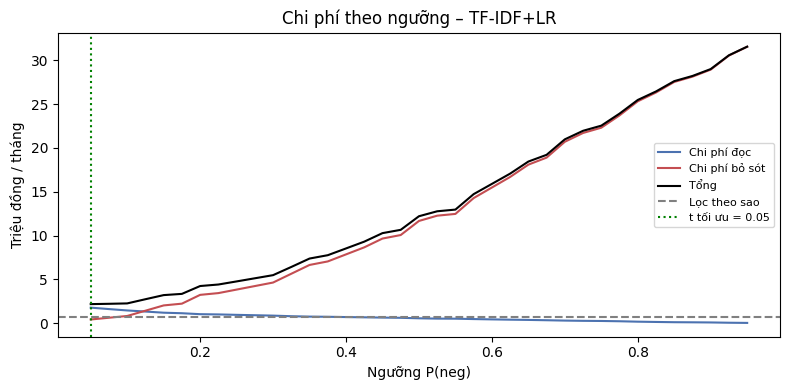

t                                 0.05
Số review phải đọc/tháng       1757.37
Bỏ sót review chê/tháng           8.04
Recall neg                        0.99
Chi phí đọc                 1757372.65
Chi phí bỏ sót               402144.77
Tổng                        2159517.43
Name: 0, dtype: float64


In [10]:
ts = np.linspace(0.05, 0.95, 37)
sweep = []
for t in ts:
    c = strategy_cost(scores[BEST_P][:, 0] >= t)
    sweep.append({"t": t, **c, "Tổng": c["Chi phí đọc"] + c["Chi phí bỏ sót"]})
sweep = pd.DataFrame(sweep)
t_best = sweep.loc[sweep["Tổng"].idxmin(), "t"]
fig, ax = plt.subplots(figsize=(8, 4))
for col, c in [("Chi phí đọc", "#4C72B0"), ("Chi phí bỏ sót", "#C44E52"), ("Tổng", "black")]:
    ax.plot(sweep.t, sweep[col] / 1e6, label=col, color=c)
ax.axhline(cost.loc["(b) Lọc theo sao (1–2 sao)", "Tổng chi phí/tháng"] / 1e6, ls="--", color="gray", label="Lọc theo sao")
ax.axvline(t_best, ls=":", color="green", label=f"t tối ưu = {t_best:.2f}")
ax.set(xlabel="Ngưỡng P(neg)", ylabel="Triệu đồng / tháng", title=f"Chi phí theo ngưỡng – {BEST_P}")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG}/cost_threshold.png", bbox_inches="tight"); plt.show()
print(sweep.loc[sweep["Tổng"].idxmin()].round(2))

### ROI 12 tháng so với cách làm hiện tại (lọc theo sao)

`ROI = (Tiết kiệm 12 tháng − Chi phí đầu tư) / Chi phí đầu tư`, trong đó Chi phí đầu tư = triển khai + 12 × vận hành.

In [11]:
def roi(c_miss, n, a=ASSUME):
    a = {**a, "C_MISS": c_miss, "N_review_thang": n}
    base = strategy_cost(strategies["(b) Lọc theo sao (1–2 sao)"], a)
    mod = strategy_cost(scores[BEST_P][:, 0] >= t_best, a)
    save = 12 * ((base["Chi phí đọc"] + base["Chi phí bỏ sót"]) - (mod["Chi phí đọc"] + mod["Chi phí bỏ sót"]))
    invest = a["CHI_PHI_TRIEN_KHAI"] + 12 * a["CHI_PHI_VAN_HANH_THANG"]
    return (save - invest) / invest

print(f"ROI 12 tháng (giả định gốc): {roi(ASSUME['C_MISS'], ASSUME['N_review_thang']):.1%}")
sens = pd.DataFrame({f"C_MISS={cm//1000}k": {f"N={n}": roi(cm, n) for n in [1000, 3000, 10000]}
                     for cm in [25_000, 50_000, 100_000]})
sens.to_csv(f"{REP}/roi_sensitivity.csv", encoding="utf-8-sig")
print("Phân tích độ nhạy ROI (hàng: số review/tháng, cột: thiệt hại khi bỏ sót):")
sens.style.format("{:.0%}")

ROI 12 tháng (giả định gốc): -186.6%
Phân tích độ nhạy ROI (hàng: số review/tháng, cột: thiệt hại khi bỏ sót):


,C_MISS=25k,C_MISS=50k,C_MISS=100k
N=1000,-125%,-129%,-137%
N=3000,-175%,-187%,-210%
N=10000,-350%,-389%,-465%


**Nhận xét (tự viết, đưa lên P1.4 và P5.1):** So với lọc theo sao, mô hình bắt thêm được những review chê nằm trong 3–5 sao (xem bảng chéo nhãn tay × sao ở notebook 03). Với giả định nào thì ROI dương? Shop nhỏ (N nhỏ) có đáng đầu tư không?

## 4. Human-in-the-loop

Câu có xác suất cao nhất < τ thì chuyển cho nhân viên xem lại. Đánh đổi: bao nhiêu % câu phải xem tay, đổi lại F1 trên phần máy tự xử lý tăng bao nhiêu?

In [12]:
P = scores[BEST_P]
conf = P.max(1)
pred = np.array(LABELS)[P.argmax(1)]
hitl = []
for tau in [0.0, 0.5, 0.6, 0.7, 0.8]:
    auto = conf >= tau
    hitl.append({"τ": tau, "% chuyển người": 1 - auto.mean(),
                 "F1-macro phần tự động": f1_score(gold.label[auto], pred[auto], average="macro") if auto.sum() else np.nan,
                 "Recall neg phần tự động": recall_score(gold.label[auto], pred[auto], labels=["neg"], average="macro") if auto.sum() else np.nan})
hitl = pd.DataFrame(hitl).round(3)
hitl.to_csv(f"{REP}/hitl.csv", index=False)
hitl

,τ,% chuyển người,F1-macro phần tự động,Recall neg phần tự động
0,0.0,0.000,0.612,0.750
1,0.5,0.109,0.639,0.791
2,0.6,0.206,0.650,0.847
3,0.7,0.322,0.663,0.877
4,0.8,0.438,0.636,0.944


## 5. Fairness: mô hình có bất lợi cho nhóm nào không?

In [13]:
fair = (gold.assign(pred=pred)
        .groupby("category")
        .apply(lambda d: pd.Series({"n": len(d), "% neg thật": (d.label == "neg").mean(),
                                    "F1-macro": f1_score(d.label, d.pred, average="macro"),
                                    "Recall neg": recall_score(d.label, d.pred, labels=["neg"], average="macro", zero_division=0)}),
               include_groups=False)
        .sort_values("F1-macro"))
fair.to_csv(f"{REP}/fairness_category.csv", encoding="utf-8-sig")
fair.round(3)

,n,% neg thật,F1-macro,Recall neg
category,,,,
Mẹ & bé,55.0,0.236,0.513,0.462
Điện tử,60.0,0.300,0.562,0.889
Đồ ăn,61.0,0.344,0.567,0.571
Mỹ phẩm,229.0,0.087,0.588,0.700
Phụ kiện xe,73.0,0.425,0.614,0.839
Thời trang,249.0,0.229,0.640,0.807
Sách – văn phòng phẩm,19.0,0.000,1.000,0.000


In [14]:
if os.path.exists(f"{REP}/unaccent_results.csv"):
    print("Văn bản không dấu (từ notebook 07):")
    display(pd.read_csv(f"{REP}/unaccent_results.csv"))

Văn bản không dấu (từ notebook 07):


,Train,ViSD test có dấu,ViSD test không dấu,Vàng có dấu,Vàng không dấu
0,A+B,0.713,0.481,0.612,0.458
1,A+B+Aug,0.717,0.457,0.618,0.527


**Nhận xét (tự viết):** Ngành có ít mẫu (n nhỏ) thì F1 không ổn định, nên nói rõ. Hai nhóm dễ bị bất lợi: (1) ngành hàng khác xa dữ liệu huấn luyện (ViSD4SA chỉ có điện thoại); (2) người gõ không dấu. Hậu quả: lời chê của họ bị bỏ sót nhiều hơn. Biện pháp: thêm dữ liệu không dấu và dữ liệu ngành đó; theo dõi F1 theo nhóm; Human-in-the-loop.

## 6. XAI: giá trị SHAP của TF-IDF + Logistic Regression

Với mô hình tuyến tính, SHAP có công thức chính xác (đúng với `shap.LinearExplainer`):

φ(từ j, lớp c) = w[c, j] × (x_j − E[x_j])

- `w`: hệ số của LR.
- `x_j`: giá trị TF-IDF của từ j trong câu.
- `E[x_j]`: trung bình trên tập train.

φ > 0 nghĩa là từ đó đẩy dự đoán **về phía** lớp c. Tổng φ cộng giá trị gốc ra đúng logit của câu. Code dưới tự tính nên không cần cài thư viện `shap`. Nếu muốn vẽ bằng `shap`, xem ô cuối.

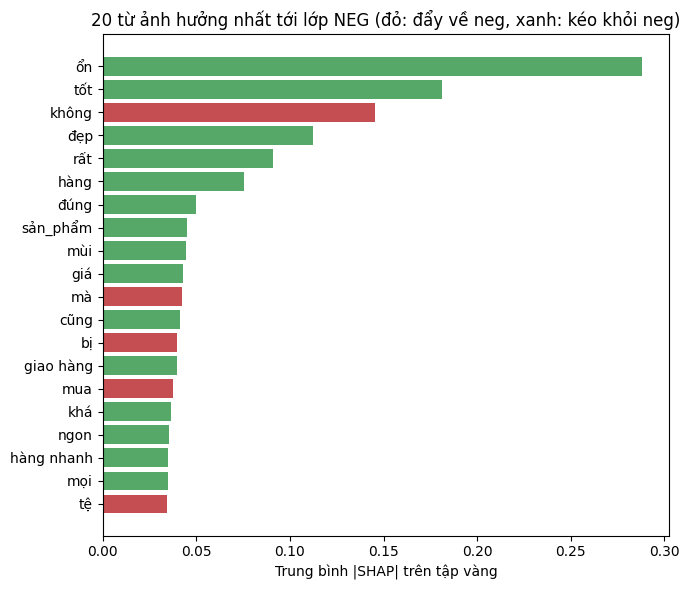

In [15]:
lr_pipe = fitted["TF-IDF+LR"]
ct, clf = lr_pipe.named_steps["vec"], lr_pipe.named_steps["clf"]
vocab = np.array([v.split("__", 1)[1] for v in ct.get_feature_names_out()])
S_ = load_sets()
X_train = ct.transform(pd.concat([S_["A"], S_["B"]])[["text_prep", "text_raw"]])
mu = np.asarray(X_train.mean(0)).ravel()
Xg_t = ct.transform(Xg)
k_neg = list(clf.classes_).index("neg")

def shap_linear(x_row, k):
    """SHAP của một câu (x_row: 1 dòng sparse)."""
    return (x_row.toarray().ravel() - mu) * clf.coef_[k]

def mean_abs_shap(X, k):
    """Trung bình |SHAP| mỗi từ trên cả tập, tính trên ma trận thưa (không đổi sang dense ~110 nghìn cột)."""
    X = X.tocsc()
    n, w = X.shape[0], np.abs(clf.coef_[k])
    nnz = np.diff(X.indptr)
    s = np.array([np.abs(X.data[X.indptr[j]:X.indptr[j + 1]] - mu[j]).sum() for j in range(X.shape[1])])
    return (s + (n - nnz) * mu) * w / n          # dòng không chứa từ j: |0 − mu_j| = mu_j

imp = pd.DataFrame({"từ": vocab, "mean|SHAP|": mean_abs_shap(Xg_t, k_neg), "hệ số neg": clf.coef_[k_neg]})
top = imp.sort_values("mean|SHAP|", ascending=False).head(20)[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top["từ"], top["mean|SHAP|"], color=np.where(top["hệ số neg"] > 0, "#C44E52", "#55A868"))
plt.title("20 từ ảnh hưởng nhất tới lớp NEG (đỏ: đẩy về neg, xanh: kéo khỏi neg)")
plt.xlabel("Trung bình |SHAP| trên tập vàng")
plt.tight_layout(); plt.savefig(f"{FIG}/shap_global_neg.png", bbox_inches="tight"); plt.show()

**Tự kiểm tra:** Có tên sản phẩm, thương hiệu hay từ chỉ ngành hàng trong top không? Nếu có, mô hình học **lối tắt** (ví dụ "đồng_hồ" bị gắn với neg chỉ vì sản phẩm đồng hồ trong tập train bị chê nhiều). Đây là một rủi ro cần nêu ở mục đạo đức.

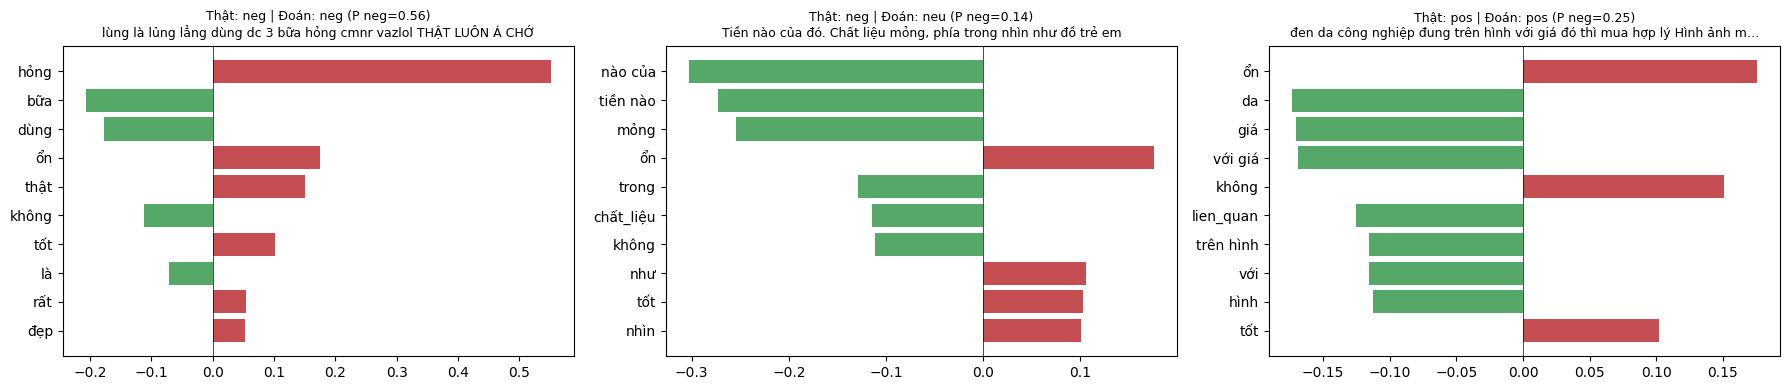

In [16]:
def explain(i, k=k_neg, top=10, ax=None):
    p = shap_linear(Xg_t[i], k)
    nz = np.argsort(np.abs(p))[::-1][:top]
    nz = nz[np.abs(p[nz]) > 0][::-1]
    ax = ax or plt.gca()
    ax.barh(vocab[nz], p[nz], color=np.where(p[nz] > 0, "#C44E52", "#55A868"))
    txt = gold.text_raw.iloc[i]
    ax.set_title(f"Thật: {gold.label.iloc[i]} | Đoán: {pred[i]} (P neg={scores['TF-IDF+LR'][i, 0]:.2f})\n"
                 f"{txt[:70]}{'…' if len(txt) > 70 else ''}", fontsize=9)
    ax.axvline(0, color="k", lw=0.5)

pred_lr = np.array(LABELS)[scores["TF-IDF+LR"].argmax(1)]
ok = np.where((pred_lr == gold.label.values) & (gold.label.values == "neg"))[0]
wrong = np.where((pred_lr != gold.label.values) & (gold.label.values == "neg"))[0]
negation = np.where(gold.text_prep.str.contains(r"\bkhông\b").values & (gold.label.values != "neg"))[0]
picks = [x[0] for x in (ok, wrong, negation) if len(x)]
fig, axes = plt.subplots(1, len(picks), figsize=(6 * len(picks), 4))
for a, i in zip(np.atleast_1d(axes), picks):
    explain(i, ax=a)
plt.tight_layout(); plt.savefig(f"{FIG}/shap_local.png", bbox_inches="tight"); plt.show()

Ba ví dụ lần lượt là: một câu chê **đoán đúng**, một câu chê **bị bỏ sót**, và một câu có "không" nhưng **không phải lời chê**. Hãy đổi chỉ số trong `picks` để chọn ví dụ dễ giải thích hơn cho báo cáo.

In [17]:
# (Tùy chọn) Vẽ bằng thư viện shap: pip install shap
try:
    import shap
    expl = shap.LinearExplainer(clf, X_train, feature_names=vocab)
    sv = expl(Xg_t)
    shap.plots.beeswarm(sv[:, :, k_neg], max_display=15, show=False)
    plt.savefig(f"{FIG}/shap_beeswarm_neg.png", bbox_inches="tight"); plt.show()
except ImportError:
    print("Chưa cài shap, bỏ qua (đã có hình tự tính ở trên).")

Chưa cài shap, bỏ qua (đã có hình tự tính ở trên).


## 7. Xuất câu sai để phân tích lỗi

Mở `report/error_analysis.csv` và điền cột `nhom_loi` cho 20–30 câu: phủ định, mỉa mai, khía cạnh trái chiều, teencode/không dấu, câu chỉ mô tả, nhãn tay có thể sai.

In [18]:
err = gold.assign(pred=pred, p_max=conf.round(2))[pred != gold.label.values]
err = err[["id", "category", "rating", "label", "pred", "p_max", "text_raw"]].sample(min(40, len(err)), random_state=42)
err["nhom_loi"] = ""
out = f"{REP}/error_analysis.csv"
if os.path.exists(out) and pd.read_csv(out).nhom_loi.notna().any():
    print("Đã có file phân tích lỗi bạn đang điền, không ghi đè.")
else:
    err.to_csv(out, index=False, encoding="utf-8-sig")
print(len(err), "câu sai đã xuất")
err.head(10)

40 câu sai đã xuất


,id,category,rating,label,pred,p_max,text_raw,nhom_loi
218,shp_0718,Điện tử,3,neu,neg,0.81,"Bóc hộp ra thấy bị vết như này, thất vọng appl...",
21,shp_0215,Thời trang,3,neu,neg,0.73,lỏ đen k Xước nhiều,
278,shp_0911,Mẹ & bé,2,neg,pos,0.49,dày bthg vải bông Tr ơi. Mình kiểu mua thay ch...,
216,shp_0716,Điện tử,4,pos,neg,0.46,"Hài lòng san pham , giao nhanh, tru caia vouch...",
73,shp_0449,Phụ kiện xe,3,neu,neg,0.51,Tiền nào của đó. Chất lượng tròng nhựa của kín...,
411,shp_1246,Đồ ăn,2,neg,neu,0.54,ngon mà cho không nhiều Nói thiệt chứ nó ngon ...,
342,shp_1043,Thời trang,2,neg,neu,0.82,"da mút Hàng chật, kích k thể mặc vừa đc, chọn ...",
474,shp_1381,Thời trang,5,pos,neu,0.96,"nhựa , cao su xanh biển cũng tạm Cũng nên mua",
161,shp_0537,Mỹ phẩm,2,neg,neu,0.47,hàng tặng kèm thì cũ bẩn không còn nguyên lớp ...,
74,shp_0450,Phụ kiện xe,3,neu,neg,0.51,Kính khi đeo tròng với kính cận ko hề thoải má...,
